# 5R4C with two envelope nodes and internal mass — heat balance and state-space matrices

```
                                     Phi_HC
                                       |
   T_a ---R_e1a--- T_e1 ---R_ie1---+   |
                    |              |   |
                   C_e1            T_i ---R_im--- T_m
                                   |   |           |
   T_out -R_e2out- T_e2 ---R_ie2---+  C_i         C_m
                    |
                   C_e2
```

| symbol | unit | meaning |
|---|---|---|
| $T_i$ | °C | indoor air (state, measured) |
| $T_{e1}$ | °C | envelope part facing the surrounding room (state, hidden) |
| $T_{e2}$ | °C | envelope part facing the outdoor air (state, hidden) |
| $T_m$ | °C | internal mass: stored products, shelves (state, hidden) |
| $T_a$ | °C | surrounding room (disturbance) |
| $T_{out}$ | °C | outdoor air, `temperature_2m` (disturbance) |
| $\Phi_{HC}$ | W | cooling (<0) power (control), $\Phi_{HC} = -P_{el}$, supplied to the air only |
| $R_{i,e1}$, $R_{i,e2}$ | K/W | air ↔ envelope inner surfaces |
| $R_{e1,a}$ | K/W | envelope 1 ↔ surrounding room |
| $R_{e2,out}$ | K/W | envelope 2 ↔ outdoor air |
| $R_{im}$ | K/W | air ↔ internal mass |
| $C_i$, $C_{e1}$, $C_{e2}$, $C_m$ | J/K | node capacities |

In [1]:
import numpy as np
import sympy as sp
from IPython.display import display, Math

sp.init_printing()

def show(lhs, expr):
    display(Math(lhs + " = " + sp.latex(expr)))

## Heat balances

$$C_i \frac{dT_i}{dt} = \frac{T_{e1} - T_i}{R_{i,e1}} + \frac{T_{e2} - T_i}{R_{i,e2}} + \frac{T_m - T_i}{R_{im}} + \Phi_{HC}$$

$$C_{e1} \frac{dT_{e1}}{dt} = \frac{T_i - T_{e1}}{R_{i,e1}} + \frac{T_a - T_{e1}}{R_{e1,a}}$$

$$C_{e2} \frac{dT_{e2}}{dt} = \frac{T_i - T_{e2}}{R_{i,e2}} + \frac{T_{out} - T_{e2}}{R_{e2,out}}$$

$$C_m \frac{dT_m}{dt} = \frac{T_i - T_m}{R_{im}}$$

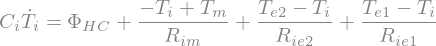

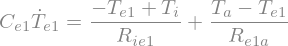

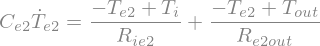

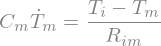

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [2]:
T_i, T_e1, T_e2, T_m, T_a, T_out, Phi_HC = sp.symbols("T_i T_e1 T_e2 T_m T_a T_out Phi_HC", real=True)
R_ie1, R_e1a, R_ie2, R_e2out, R_im = sp.symbols("R_ie1 R_e1a R_ie2 R_e2out R_im", positive=True)
C_i, C_e1, C_e2, C_m = sp.symbols("C_i C_e1 C_e2 C_m", positive=True)
dT_i, dT_e1, dT_e2, dT_m = sp.symbols(r"\dot{T}_i \dot{T}_{e1} \dot{T}_{e2} \dot{T}_m")

balances = [
    sp.Eq(C_i * dT_i,   (T_e1 - T_i) / R_ie1 + (T_e2 - T_i) / R_ie2 + (T_m - T_i) / R_im + Phi_HC),
    sp.Eq(C_e1 * dT_e1, (T_i - T_e1) / R_ie1 + (T_a - T_e1) / R_e1a),
    sp.Eq(C_e2 * dT_e2, (T_i - T_e2) / R_ie2 + (T_out - T_e2) / R_e2out),
    sp.Eq(C_m * dT_m,   (T_i - T_m) / R_im),
]
for b in balances:
    display(b)

dx = [dT_i, dT_e1, dT_e2, dT_m]
sol = sp.solve(balances, dx, dict=True)[0]
f = sp.Matrix([sp.expand(sol[v]) for v in dx])
for v, fi in zip(dx, f):
    show(sp.latex(v), fi)

## State-space form

The balances are linear in the states $x$, the control $u$ and the disturbances $d$, so

$$\dot x = A x + B u + E d, \qquad A = \frac{\partial f}{\partial x},\; B = \frac{\partial f}{\partial u},\; E = \frac{\partial f}{\partial d}.$$

The Jacobians are taken symbolically below, and the cell after that checks that $A x + B u + E d$ reproduces $f$ exactly.

In [3]:
x = sp.Matrix([T_i, T_e1, T_e2, T_m])
u = sp.Matrix([Phi_HC])
d = sp.Matrix([T_a, T_out])
A = f.jacobian(x)
B = f.jacobian(u)
E = f.jacobian(d)

show(r"x", x); show(r"u", u); show(r"d", d)
show(r"A", A)
show(r"B", B)
show(r"E", E)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [4]:
assert sp.simplify(A * x + B * u + E * d - f) == sp.zeros(*f.shape)
print("A x + B u + E d == f  ✓")

A x + B u + E d == f  ✓


## Steady state

In steady state no heat flows into the capacities. Each envelope node then lies on the straight line of its series path, $T_{e1} = (R_{e1,a} T_i + R_{i,e1} T_a)/(R_{i,e1} + R_{e1,a})$ (this is what the `static_inversion` initialization uses), the mass equals the air, and the air settles at

$$T_{i,ss} = \frac{T_a/R_1 + T_{out}/R_2 + \Phi_{HC}}{1/R_1 + 1/R_2}, \qquad R_1 = R_{i,e1} + R_{e1,a}, \quad R_2 = R_{i,e2} + R_{e2,out}.$$

So in steady state the model looks like the 3R2C outdoor-link model with $R_{ia} = R_1$ and $R_{i,out} = R_2$; the envelope capacities only shape the transients.

In [5]:
ss = sp.solve(list(f), list(x), dict=True)[0]
for v in x:
    show(sp.latex(v) + r"_{,ss}", sp.simplify(ss[v]))

R1, R2 = R_ie1 + R_e1a, R_ie2 + R_e2out
T_i_ss = (T_a / R1 + T_out / R2 + Phi_HC) / (1 / R1 + 1 / R2)
assert sp.simplify(ss[T_i] - T_i_ss) == 0
assert sp.simplify(ss[T_e1] - (R_e1a * ss[T_i] + R_ie1 * T_a) / R1) == 0
assert sp.simplify(ss[T_e2] - (R_e2out * ss[T_i] + R_ie2 * T_out) / R2) == 0
assert sp.simplify(ss[T_m] - ss[T_i]) == 0
print("steady state formulas  ✓")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

steady state formulas  ✓

## Time constants

$A$ is 4×4, so the time constants $\tau_k = -1/\lambda_k(A)$ are computed numerically (`FiveR4CInternalMass.time_constants`). For the example values below, the fastest mode is the air, the slowest the internal mass or the envelope, depending on the capacities.

In [6]:
example = {R_ie1: 0.005, R_e1a: 0.05, R_ie2: 0.01, R_e2out: 0.2, R_im: 0.002,
           C_i: 5e4, C_e1: 2e5, C_e2: 1e5, C_m: 3e5}
A_ex = np.array(A.subs(example), dtype=float)
print("time constants [min]:", np.round(np.sort(-1 / np.linalg.eigvals(A_ex).real) / 60, 2))

time constants [min]: [  0.96  12.93  15.64 451.7 ]


## Discretization (as implemented in the toolbox)

With the inputs held constant over each step (zero-order hold), the exact one-step map is

$$x_k = A_d x_{k-1} + B_d \begin{bmatrix} u_k \\ d_k \end{bmatrix}, \qquad A_d = e^{A\,\Delta t}, \qquad B_d = \int_0^{\Delta t} e^{A s}\,ds\,[B \;\; E],$$

which `rctoolbox.models.discretization.zoh_discretize` evaluates with the augmented-matrix exponential

$$\exp\!\left(\begin{bmatrix} A & [B\;E] \\ 0 & 0 \end{bmatrix}\Delta t\right) = \begin{bmatrix} A_d & B_d \\ 0 & I \end{bmatrix}.$$

The input column order is therefore the stacked vector $[u; d]$ used by `calc_temperature`. The forward-Euler option steps $x_k = x_{k-1} + \Delta t\,(A x_{k-1} + B u_k + E d_k)$, which is stable only for $\Delta t < 2\tau_{\min}$.

## Check against the toolbox implementation

The symbolic matrices are evaluated for random parameter values and compared with `calc_matrices()` of the model class.

In [7]:
from rctoolbox.models.rc.five_r4c_im.model import FiveR4CInternalMass

rng = np.random.default_rng(0)
for _ in range(5):
    p = {"R_ie1": rng.uniform(1e-4, 1), "R_e1a": rng.uniform(1e-3, 10),
         "R_ie2": rng.uniform(1e-4, 1), "R_e2out": rng.uniform(1e-3, 10), "R_im": rng.uniform(1e-4, 1),
         "C_i": rng.uniform(1e3, 1e7), "C_e1": rng.uniform(1e3, 1e8),
         "C_e2": rng.uniform(1e3, 1e8), "C_m": rng.uniform(1e4, 1e8)}
    model = FiveR4CInternalMass()
    model.set_params(p)
    A_num, B_num, E_num = model.calc_matrices()

    subs = {R_ie1: p["R_ie1"], R_e1a: p["R_e1a"], R_ie2: p["R_ie2"], R_e2out: p["R_e2out"], R_im: p["R_im"],
            C_i: p["C_i"], C_e1: p["C_e1"], C_e2: p["C_e2"], C_m: p["C_m"]}
    for name, S, N in [("A", A, A_num), ("B", B, B_num), ("E", E, E_num)]:
        S_num = np.array(S.subs(subs), dtype=float)
        assert np.allclose(S_num, N, rtol=1e-12, atol=0), name
print("symbolic A, B, E == FiveR4CInternalMass.calc_matrices()  ✓")

symbolic A, B, E == FiveR4CInternalMass.calc_matrices()  ✓
